In [5]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\USER\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [6]:
pip install seabornimport

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\USER\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = sns.load_dataset("taxis")
print(df.head())

Matplotlib is building the font cache; this may take a moment.


               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [2]:
print(df.shape)

(6433, 14)


In [3]:
print(df.isnull().sum())


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [5]:

df['payment'] = df['payment'].fillna(df['payment'].mode()[0])
df['pickup_zone'] = df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])
df['dropoff_zone'] = df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])
df['pickup_borough'] = df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])
df['dropoff_borough'] = df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [6]:
df['pickup'] = pd.to_datetime(df['pickup'])

print(df['pickup'].dtype)

datetime64[us]


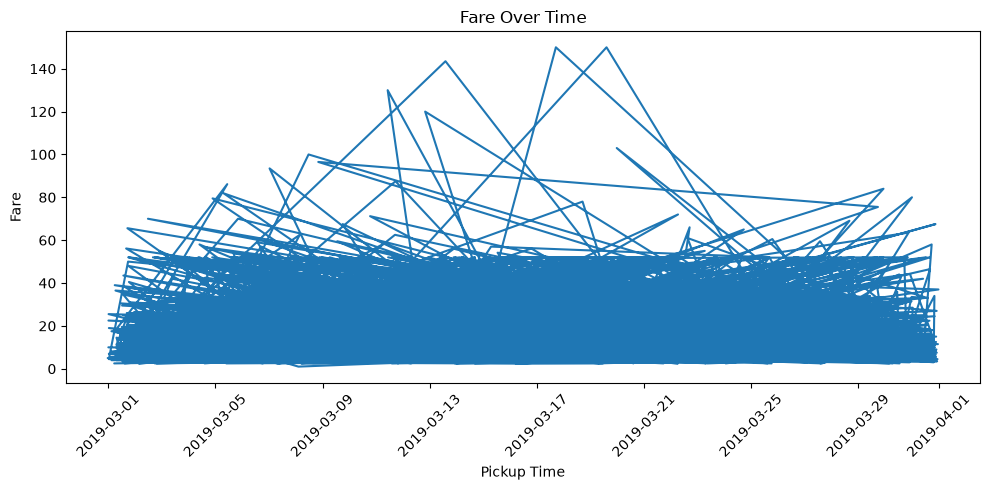

In [7]:
plt.figure(figsize=(10,5))

plt.plot(df['pickup'], df['fare'])

plt.title('Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [8]:
borough_fare = df.groupby('pickup_borough')['fare'].sum()

print(borough_fare)

pickup_borough
Bronx         2078.91
Brooklyn      6327.48
Manhattan    59426.42
Queens       16382.06
Name: fare, dtype: float64


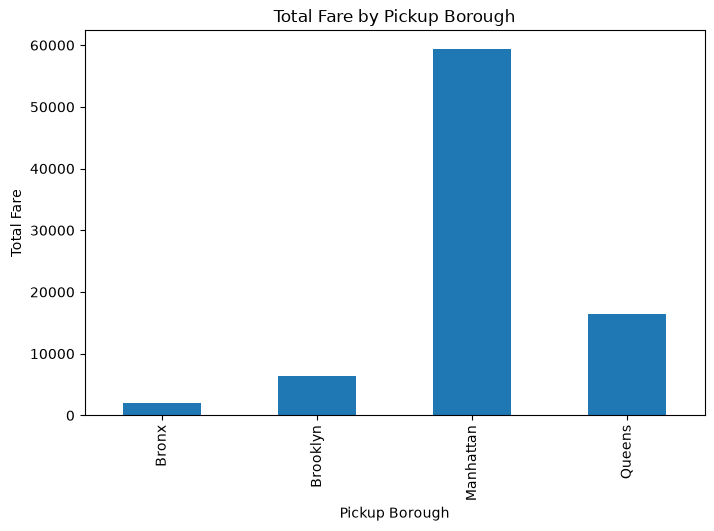

In [9]:
borough_fare.plot(kind='bar', figsize=(8,5))

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

plt.show()

In [10]:
payment_count = df['payment'].value_counts()

print(payment_count)

payment
credit card    4621
cash           1812
Name: count, dtype: int64


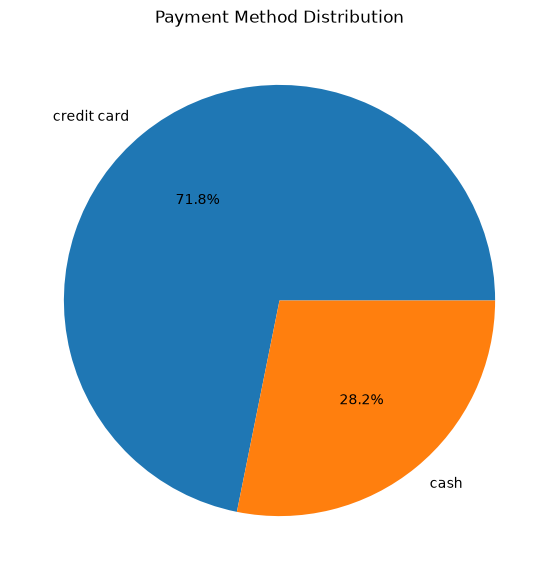

In [11]:
plt.figure(figsize=(7,7))

plt.pie(
    payment_count,
    labels=payment_count.index,
    autopct='%1.1f%%'
)

plt.title('Payment Method Distribution')

plt.show()


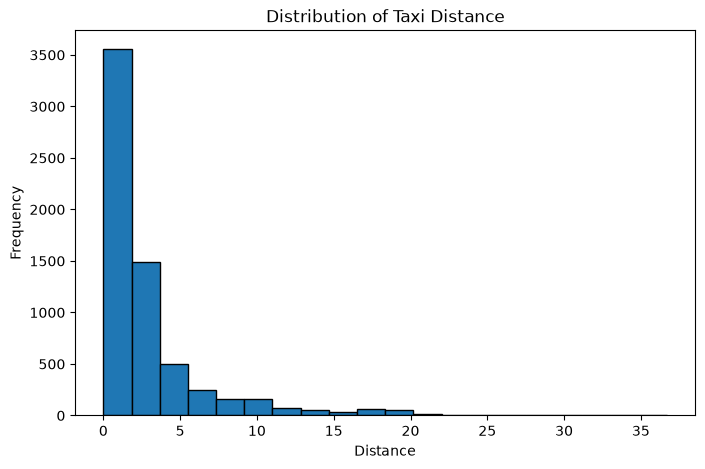

In [12]:
plt.figure(figsize=(8,5))

plt.hist(df['distance'], bins=20, edgecolor='black')

plt.title('Distribution of Taxi Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')

plt.show()

<Figure size 900x500 with 0 Axes>

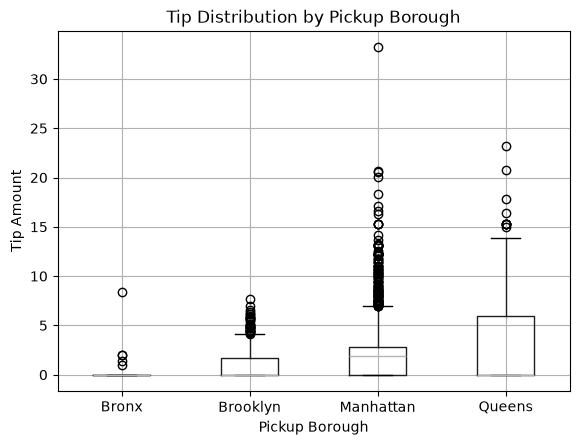

In [13]:
plt.figure(figsize=(9,5))

df.boxplot(column='tip', by='pickup_borough')

plt.title('Tip Distribution by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.show()

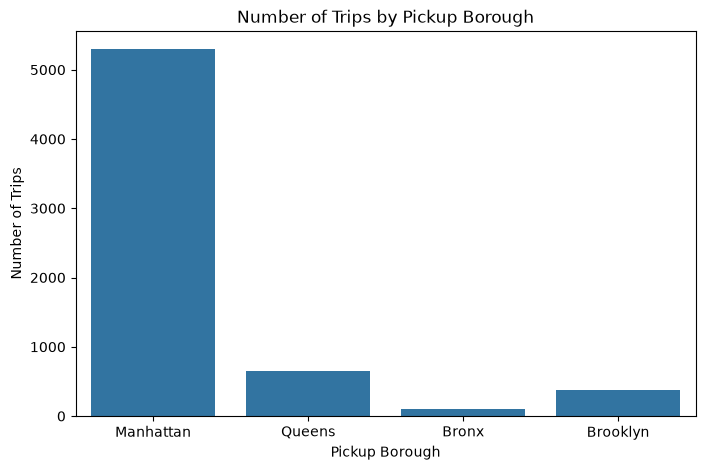

In [14]:


plt.figure(figsize=(8,5))

sns.countplot(data=df, x='pickup_borough')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

plt.show()

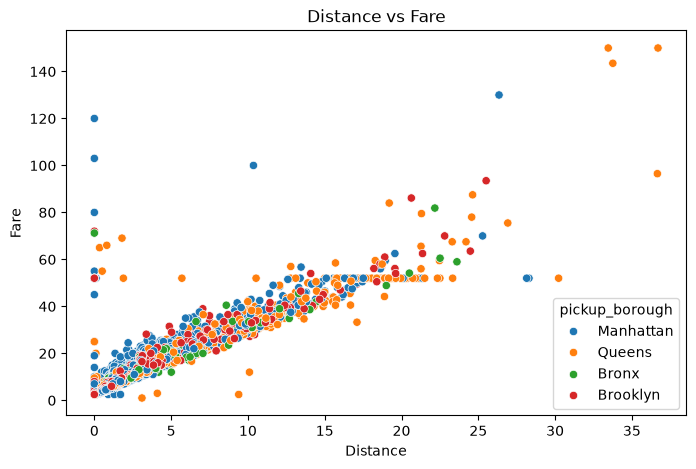

In [15]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.title('Distance vs Fare')
plt.xlabel('Distance')
plt.ylabel('Fare')

plt.show()

In [16]:
corr = df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()

print(corr)

          distance      fare       tip     tolls     total
distance  1.000000  0.920108  0.452589  0.635267  0.904676
fare      0.920108  1.000000  0.488612  0.609307  0.974358
tip       0.452589  0.488612  1.000000  0.413619  0.646186
tolls     0.635267  0.609307  0.413619  1.000000  0.683142
total     0.904676  0.974358  0.646186  0.683142  1.000000


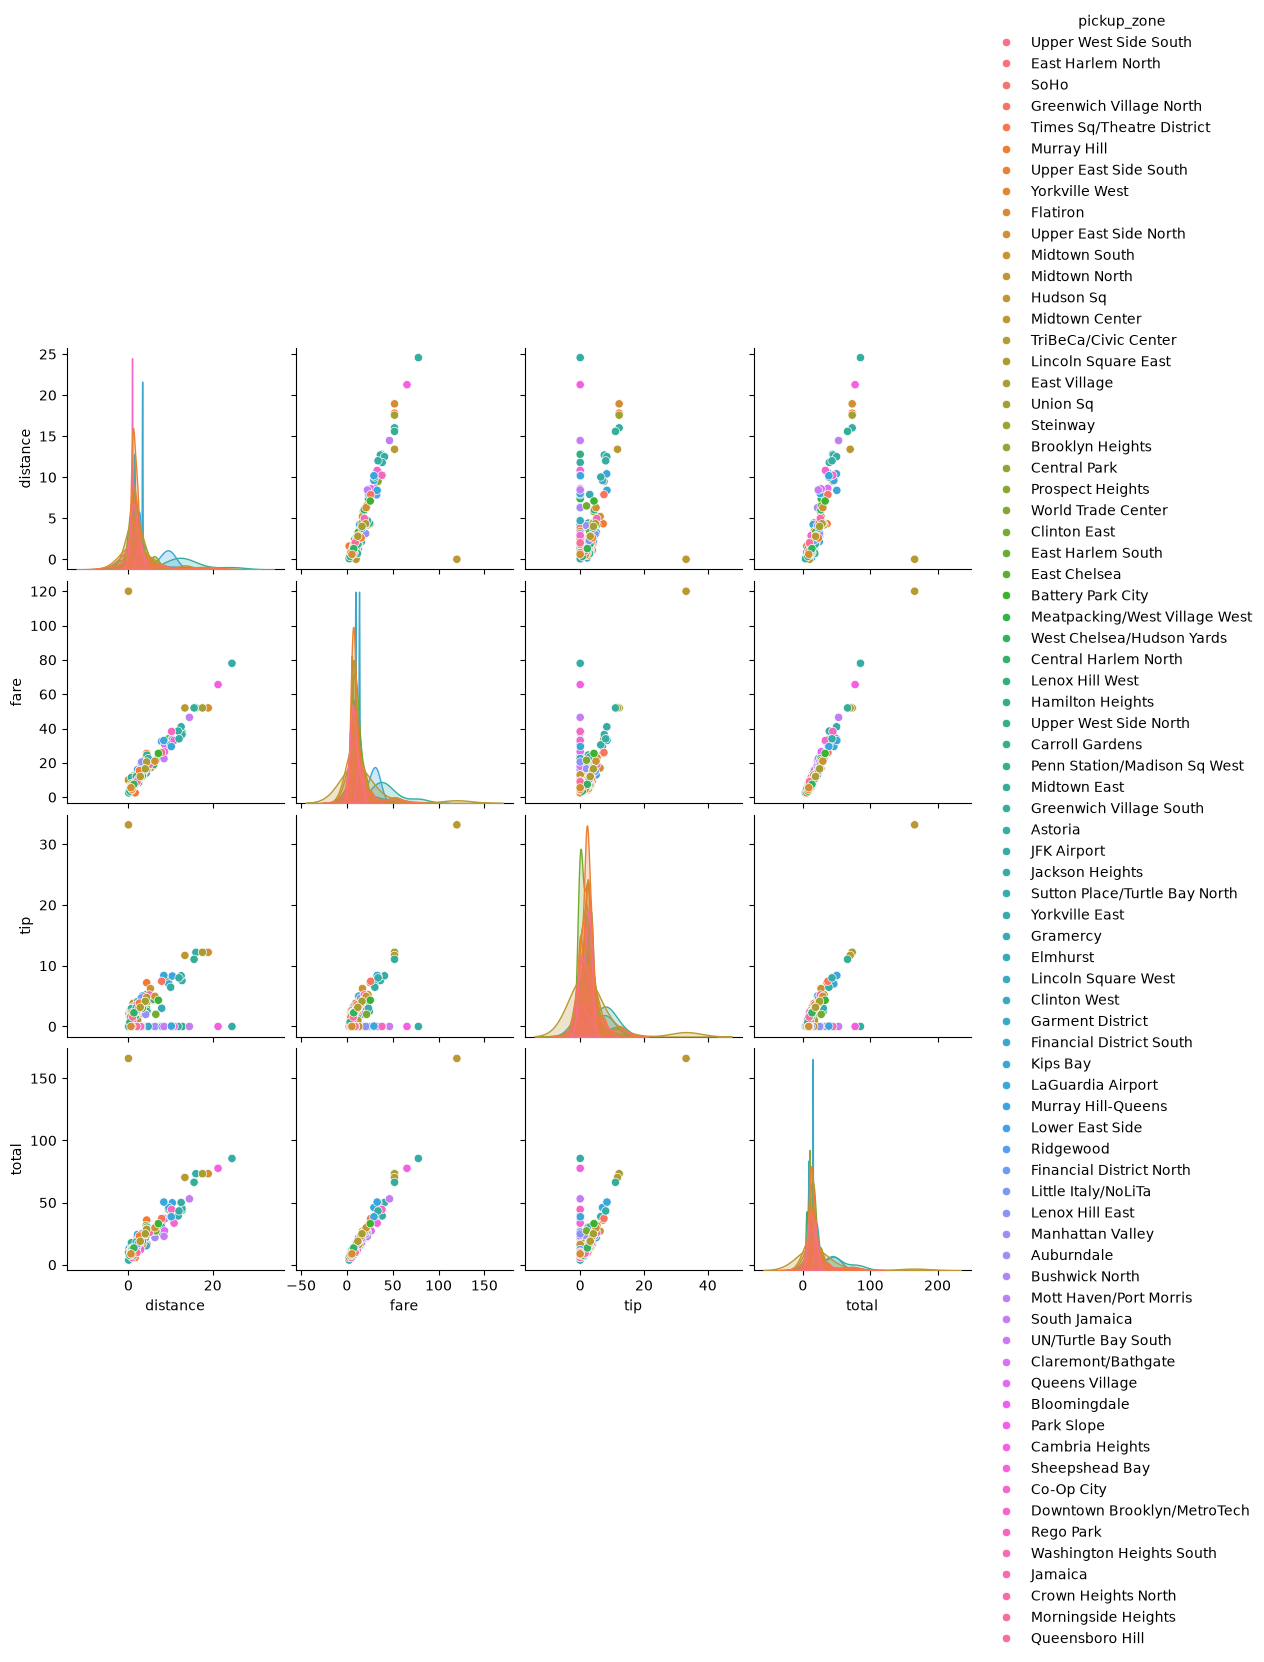

In [17]:
sample_df = df[['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna().sample(
    n=300, random_state=42
)

sns.pairplot(sample_df, hue='pickup_zone')

plt.show()

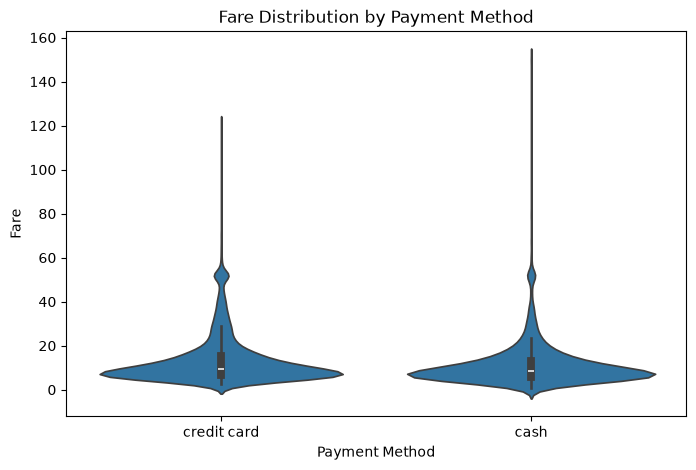

In [18]:
plt.figure(figsize=(8,5))

sns.violinplot(
    data=df,
    x='payment',
    y='fare'
)

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')

plt.show()